In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Blocks, Bottlenecks, and Branches: VGG, NiN, GoogLeNet

AlexNet (that section) specifies each of its eight layers by hand:
an $11 \times 11$ kernel here, 384 channels there, a pooling layer after the
first, second, and fifth convolutions. That works for eight layers, but a
designer who wants twenty needs a rule for choosing them. AlexNet also puts
92% of its 47 million parameters into its fully connected head, where they
do 5% of the arithmetic and have to be held back from memorizing the training
set by dropout. Three networks of 2013 and 2014 answered these two problems
with ideas that every later convolutional network uses.

VGG [@Simonyan.Zisserman.2014] builds the network from one repeated
*block*, a few $3 \times 3$ convolutions followed by pooling, so that a whole
network is a short list of block sizes. Network in network (NiN)
[@Lin.Chen.Yan.2013] removes the fully connected head: $1 \times 1$
convolutions mix the channels at every position, and an average over all
positions turns the last feature map into class scores. GoogLeNet
[@Szegedy.Liu.Jia.ea.2015] runs convolutions of several sizes in
parallel inside one block and makes the expensive ones affordable by first
reducing the number of channels with $1 \times 1$ convolutions. We build each
network, count its parameters and multiply-adds as we did for AlexNet, and
train it on Fashion-MNIST under the same procedure, so that the four networks
can be compared on one table.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## VGG: Blocks as the Unit of Design

VGG replaces individually chosen layers with one block, repeated at growing
channel counts. The block answers two questions at once: how to make a
network deeper without losing its resolution too soon, and how large its
kernels should be.

### Stacks of $3 \times 3$ Convolutions

If every convolution were followed by pooling with stride 2, an input of
width $d$ would permit at most $\lfloor\log_2 d\rfloor$ convolutions before
its spatial extent collapses: for a 224-pixel image, 224, 112, 56, 28, 14, 7,
3, 1, and the network is over after seven halvings. To go deeper, a network
must place several convolutions at each resolution, with stride 1 and
padding that keeps the size.

VGG places small kernels there. Two stacked $3 \times 3$ convolutions see a
$5 \times 5$ window of their input, the same as one $5 \times 5$
convolution, but with $c$ input and $c$ output channels they have
$2 \cdot 9c^2 = 18c^2$ weights instead of $25c^2$. Three of them see
$7 \times 7$ with $27c^2$ weights instead of $49c^2$, and they apply three
nonlinearities instead of one. @Simonyan.Zisserman.2014 trained
networks of 11 to 19 layers built this way and found that the deeper ones
classified ImageNet more accurately. Stacks of $3 \times 3$ convolutions
remained the default for most of the following decade, and GPU libraries implement them with
specialized algorithms [@lavin2016fast].

A *VGG block* is therefore a sequence of `num_convs` $3 \times 3$
convolutions with padding 1, each followed by a ReLU, and a $2 \times 2$
max-pooling with stride 2 at the end. The convolutions keep the height and
the width; the pooling halves them.

In [2]:
def vgg_block(num_convs, in_channels, out_channels, init):
    layers = []
    for _ in range(num_convs):
        layers.append(nnx.Conv(in_channels, out_channels, kernel_size=(3, 3),
                               padding=(1, 1), **init))
        layers.append(nnx.relu)
        in_channels = out_channels
    layers.append(max_pool)
    return nnx.Sequential(*layers)

def max_pool(x):  # 2x2 windows, stride 2
    return nnx.max_pool(x, window_shape=(2, 2), strides=(2, 2))

### The VGG Network

A VGG network is a sequence of such blocks followed by the fully connected
head of AlexNet: two hidden layers of 4096 units with dropout, and an output
layer. the figure places VGG-11 beside AlexNet. Every block halves the
resolution, so five blocks take a $224 \times 224$ input to $7 \times 7$,
and the number of channels doubles from block to block up to 512.

![AlexNet (left) and VGG-11 (right) for single-channel $224 \times 224$ images and ten classes; the input is at the bottom. AlexNet's layers are chosen one by one; VGG repeats one block, several $3 \times 3$ convolutions followed by max-pooling, at growing channel counts.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-vgg.svg)

Since a block is fixed by two numbers, the number of convolutions and their
output channels, the convolutional part of the network is fixed by a list of
such pairs. The class `VGG` takes this list as its argument `arch` and builds
one block per entry. VGG is therefore a *family* of networks: VGG-11, VGG-16,
and VGG-19 differ only in `arch`, and @Simonyan.Zisserman.2014
compared six members of the family. We initialize all networks of this
section as AlexNet in that section: He-normal weights and zero
biases.

The dictionary `init` carries the weight initializer and the random number
streams to every layer.

In [3]:
class VGG(d2l.Classifier):
    def __init__(self, arch, lr=0.1, num_steps=4690, num_classes=10,
                 input_shape=(224, 224, 1), rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = (nnx.Rngs(params=d2l.get_key(), dropout=d2l.get_key())
                if rngs is None else rngs)
        he = nnx.initializers.variance_scaling(2.0, 'fan_in', 'normal')
        init = dict(kernel_init=he, rngs=rngs)
        conv_blks, in_channels = [], input_shape[-1]
        for num_convs, out_channels in arch:
            conv_blks.append(vgg_block(num_convs, in_channels, out_channels,
                                       init))
            in_channels = out_channels
        # Each block halves the height and the width
        height, width = (n // 2 ** len(arch) for n in input_shape[:2])
        self.net = nnx.Sequential(
            *conv_blks,
            flatten,
            nnx.Linear(height * width * in_channels, 4096, **init), nnx.relu,
            nnx.Dropout(0.5, rngs=rngs),
            nnx.Linear(4096, 4096, **init), nnx.relu,
            nnx.Dropout(0.5, rngs=rngs),
            nnx.Linear(4096, num_classes, **init))

def flatten(x):  # One vector per example
    return x.reshape((x.shape[0], -1))

`VGG` takes the image size as `input_shape`, since NNX layers need their
input sizes when they are built: the first fully connected layer reads
$h w c$ numbers for a final feature map of $h \times w$ pixels and $c$
channels.

VGG-11, the smallest network of the paper, has five blocks: one convolution
each in the first two and two in the other three, with 64, 128, 256, 512,
and 512 output channels. Its eight convolutional and three fully connected
layers give it its name. We check the shapes on one $224 \times 224$ image.

In [4]:
VGG(arch=((1, 64), (1, 128), (2, 256), (2, 512), (2, 512))).layer_summary(
    (1, 224, 224, 1))

Sequential             (1, 112, 112, 64)


Sequential             (1, 56, 56, 128)


Sequential             (1, 28, 28, 256)


Sequential             (1, 14, 14, 512)


Sequential             (1, 7, 7, 512)
flatten                (1, 25088)


Linear                 (1, 4096)
relu                   (1, 4096)


Dropout                (1, 4096)


Linear                 (1, 4096)
relu                   (1, 4096)
Dropout                (1, 4096)


Linear                 (1, 10)


Each block halves the height and the width, from 224 to 7, and the last
block hands $512 \times 7 \times 7 = 25{,}088$ numbers to the fully connected
head. Counted as for AlexNet, VGG-11 has 128.8 million parameters and
performs 7.5 billion multiply-adds per image. Its eight convolutional layers
hold 9.2 million of the parameters and perform 98% of the arithmetic, eight
times AlexNet's convolutional arithmetic. Its head holds 119.6 million
parameters, 93% of the total; the first fully connected layer alone,
$25{,}088 \times 4096$, holds 103 million, about 410 MB in 32-bit floating
point.

### Training

VGG-11 performs eight times the arithmetic of AlexNet, so we train a
narrower member of the family on Fashion-MNIST, with a quarter of the
channels in every block: 16, 32, 64, 128, and 128. It performs 512 million
multiply-adds per image, 470 million of them in the convolutions: about half
of AlexNet's 938 million. Everything else
follows that section: images upsampled to $224 \times 224$,
minibatches of 128, and 10 epochs of SGD whose learning rate rises linearly
to a peak of 0.03 over the first epoch and then decays to zero along the
half-cosine the equation, stepped after every minibatch. VGG
gets the same `configure_optimizers` as AlexNet.

In [5]:
@d2l.add_to_class(VGG)
def configure_optimizers(self):
    return optax.sgd(lambda t: self.lr * d2l.cosine_warmup(
        t, self.num_steps, self.num_steps // 10))

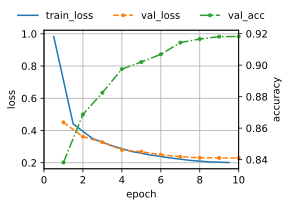

In [6]:
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model = VGG(arch=((1, 16), (1, 32), (2, 64), (2, 128), (2, 128)), lr=0.03,
            num_steps=10 * len(data.train_dataloader()))
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)
val_acc = {'VGG': trainer.history['val_acc']}  # for the comparison below

The narrow VGG reaches a validation accuracy of about 92%, half a point to a
point above AlexNet with half of its arithmetic, and the training and
validation losses stay close. Narrowing the blocks shrank the convolutions
to 0.6 million parameters, but the head still maps
$128 \times 7 \times 7 = 6272$ numbers to 4096 units and holds 42.5 million
of the network's 43.1 million parameters: 99%. Blocks organized the body of the network; the head is
untouched.

## NiN: $1 \times 1$ Convolutions and Global Average Pooling

The fully connected head is expensive because it connects every position of
the last feature map to every hidden unit, and it needs those connections
only to turn a feature map into one score per class. Inserting fully
connected layers earlier, to let the network compute more per position,
would destroy the spatial structure and cost even more. NiN solves both
problems with layers that the reader has met in that section.

### NiN Blocks

A $1 \times 1$ convolution is a fully connected layer applied independently
at every pixel: it maps the $c_\textrm{i}$ channels at a position to
$c_\textrm{o}$ channels with the same $c_\textrm{i} \times c_\textrm{o}$
weight matrix at every position, and leaves the spatial structure untouched.
A *NiN block* follows an ordinary convolution with two $1 \times 1$
convolutions, each with a ReLU. The two together form a small MLP with one
hidden layer that runs at every pixel, hence the name *network in network*.
the figure compares the head of VGG with the end of NiN.

![The head of VGG (left) and the end of NiN (right), both for ten classes; the input is at the bottom. VGG flattens its last feature map into fully connected layers. After dropout, NiN's last block, a $3 \times 3$ convolution and two $1 \times 1$ convolutions with no ReLU after the last one, emits one channel per class, and global average pooling turns each channel into one score.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-nin.svg)

In [7]:
def nin_block(in_channels, out_channels, kernel_size, strides, padding,
              init, final=False):
    layers = [
        nnx.Conv(in_channels, out_channels, kernel_size, strides=strides,
                 padding=padding, **init), nnx.relu,
        nnx.Conv(out_channels, out_channels, kernel_size=(1, 1), **init),
        nnx.relu,
        nnx.Conv(out_channels, out_channels, kernel_size=(1, 1), **init)]
    return nnx.Sequential(*layers, *([] if final else [nnx.relu]))

### Global Average Pooling

NiN uses the kernel sizes and channel counts of AlexNet's first layers: blocks
with $11 \times 11$, $5 \times 5$, and $3 \times 3$ convolutions and 96, 256,
and 384 channels, each followed by $3 \times 3$ max-pooling with stride 2.
Then it differs. Its last block has as many output channels as there are
classes, ten for Fashion-MNIST, and *global average pooling* averages each of
these channels over all positions. The ten averages are the logits. The head
therefore has no parameters at all: the last block must learn to make the
channel of the correct class large on average over the image. Its last
$1 \times 1$ convolution outputs these class scores directly, without a ReLU,
and `nin_block` takes the flag `final` to drop it. A ReLU there would switch a
class off for good: once a class's pre-activations are negative at every
position of every image, its logit is 0, its gradient is zero, and training
can never bring it back. Our last block is a simplification of the original
network, whose last block stays wide, with 1,024 channels on ImageNet and 192
on CIFAR-10, until its final $1 \times 1$ convolution maps them to one channel
per class; ours narrows the whole block to ten channels.

Global average pooling has a second property. A convolution commutes with
translations, so shifting the input shifts each feature map, and an average
over all positions does not change when its entries are permuted. Up to the
borders of the image and the strides of the network, the scores therefore do
not depend on where in the image an object appears. A fully connected head,
by contrast, has a separate weight for every position.

In [8]:
class NiN(d2l.Classifier):
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10, rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = (nnx.Rngs(params=d2l.get_key(), dropout=d2l.get_key())
                if rngs is None else rngs)
        he = nnx.initializers.variance_scaling(2.0, 'fan_in', 'normal')
        init = dict(kernel_init=he, rngs=rngs)

        def max_pool(x):  # 3x3 windows, stride 2
            return nnx.max_pool(x, (3, 3), strides=(2, 2))

        self.net = nnx.Sequential(
            nin_block(1, 96, (11, 11), (4, 4), (0, 0), init), max_pool,
            nin_block(96, 256, (5, 5), (1, 1), (2, 2), init), max_pool,
            nin_block(256, 384, (3, 3), (1, 1), (1, 1), init), max_pool,
            nnx.Dropout(0.5, rngs=rngs),
            nin_block(384, num_classes, (3, 3), (1, 1), (1, 1), init,
                      final=True),
            global_avg_pool)

def global_avg_pool(x):  # Average over height and width (NHWC)
    return x.mean(axis=(1, 2))

We check the shapes on one $224 \times 224$ image.

In [9]:
NiN().layer_summary((1, 224, 224, 1))

Sequential             (1, 54, 54, 96)
max_pool               (1, 26, 26, 96)


Sequential             (1, 26, 26, 256)
max_pool               (1, 12, 12, 256)


Sequential             (1, 12, 12, 384)
max_pool               (1, 5, 5, 384)


Dropout                (1, 5, 5, 384)


Sequential             (1, 5, 5, 10)
global_avg_pool        (1, 10)


The resolution falls from 224 to 54, 26, 12, and 5, as in AlexNet, and the
last block emits ten channels of $5 \times 5$, which the pooling reduces to
ten numbers. NiN has 2.0 million parameters, 4% of AlexNet's, and performs
762 million multiply-adds per image, a little less than AlexNet's 938
million: the $1 \times 1$ convolutions add arithmetic to the body while the
head disappears.

### Training

We train NiN with the procedure of AlexNet and VGG, so it takes VGG's
`configure_optimizers`: images upsampled to $224 \times 224$, minibatches of
128, and 10 epochs of SGD whose learning rate warms up to a peak of 0.03
over the first epoch and then decays to zero. Of the peaks we tried, 0.03 is
the largest at which NiN trains reliably: at 0.05 an occasional run stays
near chance for several epochs, and at 0.1 some runs diverge.

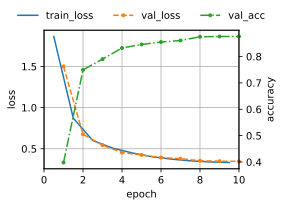

In [10]:
NiN.configure_optimizers = VGG.configure_optimizers  # AlexNet's schedule
data = d2l.FashionMNIST(batch_size=128, resize=(224, 224))
model = NiN(lr=0.03, num_steps=10 * len(data.train_dataloader()))
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)
val_acc['NiN'] = trainer.history['val_acc']

NiN ends at a validation accuracy of 84–88% after the same 10 epochs, a few
points below AlexNet and VGG, with 4% of AlexNet's parameters. Its training
loss ends between 0.3 and 0.45, against about 0.22 for AlexNet, and its
validation loss stays close to it: in 10 epochs NiN fits the training data
less well, and it does not overfit.

NiN is also the network that depends most on the learning-rate schedule.
Trained for 10 epochs at a constant rate of 0.01, it is still improving at
the end, and where a run ends, anywhere between about 78% and 87%, depends
on how quickly it leaves its first plateau. The warmup allows a peak three
times higher, which lets a slow start catch up, and the decay removes the
drops of single late epochs.

The two ideas that NiN introduced outlived the network: $1 \times 1$
convolutions for mixing channels, and global average pooling as the head of
a convolutional network.

## GoogLeNet: Multi-Branch Blocks

Which kernel size should a layer use? A $1 \times 1$ convolution sees one
position, a $5 \times 5$ convolution sees a neighborhood, and objects in
photographs come at every size. GoogLeNet, which won the ImageNet challenge
of 2014 with a top-5 error of 6.7%, does not choose: its *Inception block*
applies several kernel sizes in parallel to the same input and concatenates
their outputs. To keep the large kernels affordable it borrows NiN's
$1 \times 1$ convolution and uses it to reduce the number of channels before
each of them.

### The Inception Block

The Inception block of the figure has four parallel branches.
The first applies a $1 \times 1$ convolution. The second and third apply a
$1 \times 1$ convolution that reduces the number of channels, followed by a
$3 \times 3$ or a $5 \times 5$ convolution. The fourth applies $3 \times 3$
max-pooling with stride 1, followed by a $1 \times 1$ convolution. Every
branch pads its input so that its output keeps the height and the width, and
the block concatenates the four outputs along the channel dimension. The
numbers of output channels of the branches are the block's hyperparameters:
they decide how much of the block's capacity goes to each kernel size. The
name of the block comes from the film *Inception* and its line "we need to go
deeper".

![The Inception block; the input is at the bottom. Four parallel branches read the same input with different kernel sizes; $1 \times 1$ convolutions reduce the number of channels before the $3 \times 3$ and $5 \times 5$ convolutions; the branch outputs are concatenated along the channel dimension. The shapes are those of the first Inception block of GoogLeNet on a $224 \times 224$ input.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-inception-block.svg)

In [11]:
class Inception(nnx.Module):
    # c1--c4 are the numbers of output channels of the four branches
    def __init__(self, in_channels, c1, c2, c3, c4, init):
        self.b1_1 = nnx.Conv(in_channels, c1, kernel_size=(1, 1), **init)
        self.b2_1 = nnx.Conv(in_channels, c2[0], kernel_size=(1, 1), **init)
        self.b2_2 = nnx.Conv(c2[0], c2[1], kernel_size=(3, 3),
                             padding='SAME', **init)
        self.b3_1 = nnx.Conv(in_channels, c3[0], kernel_size=(1, 1), **init)
        self.b3_2 = nnx.Conv(c3[0], c3[1], kernel_size=(5, 5),
                             padding='SAME', **init)
        self.b4_2 = nnx.Conv(in_channels, c4, kernel_size=(1, 1), **init)

    def __call__(self, x):
        b1 = nnx.relu(self.b1_1(x))
        b2 = nnx.relu(self.b2_2(nnx.relu(self.b2_1(x))))
        b3 = nnx.relu(self.b3_2(nnx.relu(self.b3_1(x))))
        pooled = nnx.max_pool(x, window_shape=(3, 3), strides=(1, 1),
                              padding='SAME')
        b4 = nnx.relu(self.b4_2(pooled))
        return jnp.concatenate((b1, b2, b3, b4), axis=-1)

The first Inception block of GoogLeNet shows the role of the $1 \times 1$
reductions. On a $224 \times 224$ input it receives 192 channels at
$28 \times 28$ resolution, the shapes annotated in the figure.
With branch outputs $c_1 = 64$, $c_2 = (96, 128)$, $c_3 = (16, 32)$, and
$c_4 = 32$, it emits $64 + 128 + 32 + 32 = 256$ channels at the same
$28 \times 28$ resolution. A $5 \times 5$ convolution straight from 192 to
32 channels would need $25 \cdot 192 \cdot 32 = 153{,}600$ weights. Reducing
to 16 channels first costs $192 \cdot 16 = 3{,}072$ weights for the
reduction and $25 \cdot 16 \cdot 32 = 12{,}800$ for the convolution, 15,872
in total: a tenth. The number of multiply-adds falls by the same factor,
since every weight is used at all $28 \times 28$ positions. Reducing the
channels before an expensive convolution recurs throughout this chapter.

### Stem, Body, and Head

GoogLeNet has three parts, an organization that most later vision networks
share. The *stem* processes the raw image with a few ordinary convolutions
and reduces its resolution: a $7 \times 7$ convolution with stride 2 and 64
channels, max-pooling, a $1 \times 1$ convolution, a $3 \times 3$
convolution with 192 channels, and max-pooling again, each pooling with a
$3 \times 3$ window and stride 2. The *body* consists of nine Inception
blocks in three groups of two, five, and two, with max-pooling between the
groups. The *head* is NiN's: global average pooling, followed by a single
fully connected layer that maps the channels to the classes.

The channel allocations of the nine blocks come from the paper, which chose
them by hand. As for VGG, we store them as data, one tuple per block and one
tuple of blocks per group:

In [12]:
googlenet_arch = (
    ((64, (96, 128), (16, 32), 32), (128, (128, 192), (32, 96), 64)),
    ((192, (96, 208), (16, 48), 64), (160, (112, 224), (24, 64), 64),
     (128, (128, 256), (24, 64), 64), (112, (144, 288), (32, 64), 64),
     (256, (160, 320), (32, 128), 128)),
    ((256, (160, 320), (32, 128), 128), (384, (192, 384), (48, 128), 128)))

`GoogleNet` takes this tuple as its argument `arch`, as `VGG` does, and
composes the stem, the three groups with pooling in between, and the head.

In [13]:
class GoogleNet(d2l.Classifier):
    def __init__(self, arch=googlenet_arch, lr=0.1, num_steps=4690,
                 num_classes=10, rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = nnx.Rngs(d2l.get_key()) if rngs is None else rngs
        he = nnx.initializers.variance_scaling(2.0, 'fan_in', 'normal')
        init = dict(kernel_init=he, rngs=rngs)

        def pool(x):  # 3x3 windows, stride 2; 'SAME' would pad unevenly
            return nnx.max_pool(x, window_shape=(3, 3), strides=(2, 2),
                                padding=((1, 1), (1, 1)))

        stem = nnx.Sequential(
            nnx.Conv(1, 64, kernel_size=(7, 7), strides=(2, 2), padding=3,
                     **init), nnx.relu, pool,
            nnx.Conv(64, 64, kernel_size=(1, 1), **init), nnx.relu,
            nnx.Conv(64, 192, kernel_size=(3, 3), padding='SAME', **init),
            nnx.relu, pool)
        body, in_channels = [], 192
        for group in arch:
            blocks = []
            for c1, c2, c3, c4 in group:
                blocks.append(Inception(in_channels, c1, c2, c3, c4, init))
                in_channels = c1 + c2[1] + c3[1] + c4
            body.append(nnx.Sequential(*blocks))
        head = nnx.Sequential(global_avg_pool,
                              nnx.Linear(in_channels, num_classes, **init))
        self.net = nnx.Sequential(stem, body[0], pool, body[1], pool,
                                  body[2], head)

GoogLeNet has five stride-2 steps, three in the stem (the first
convolution and two poolings) and two between the groups, so it reduces the
resolution by a factor of 32. On a $96 \times 96$ input, a resolution at which Fashion-MNIST
training stays cheap, the groups operate at $12 \times 12$, $6 \times 6$, and
$3 \times 3$; the number of channels grows from 192 after the stem to 480,
832, and 1024 after the three groups.

In [14]:
GoogleNet().layer_summary((1, 96, 96, 1))

Sequential             (1, 12, 12, 192)


Sequential             (1, 12, 12, 480)
pool                   (1, 6, 6, 480)


Sequential             (1, 6, 6, 832)
pool                   (1, 3, 3, 832)


Sequential             (1, 3, 3, 1024)


Sequential             (1, 10)


GoogLeNet is the deepest network of this section: 22 layers with weights lie
on its longest path, three in the stem, two in each of the nine Inception
blocks, and the output layer. We train it with the same procedure and the
same `configure_optimizers` as the other three networks, on
$96 \times 96$ images, at which its 6.0 million parameters perform 276
million multiply-adds per image.

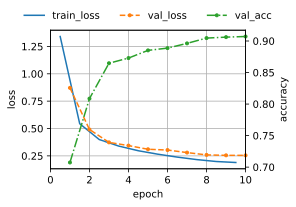

In [15]:
GoogleNet.configure_optimizers = VGG.configure_optimizers
data = d2l.FashionMNIST(batch_size=128, resize=(96, 96))
model = GoogleNet(lr=0.03, num_steps=10 * len(data.train_dataloader()))
trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
trainer.fit(model, data)
val_acc['GoogLeNet'] = trainer.history['val_acc']

GoogLeNet ends at a validation accuracy of about 91% after 10 epochs, as
AlexNet does. Its training loss, below 0.2 after 10 epochs, is lower than
AlexNet's, and its validation loss, about 0.25, is the same.

## Comparing the Networks

Since the learning rate decays to zero, the validation accuracy of every
network changes little over the last epochs, and we compare the networks by
their accuracy after the last epoch:

In [16]:
{name: round(acc[-1], 3) for name, acc in val_acc.items()}  # After 10 epochs

{'VGG': 0.918, 'NiN': 0.876, 'GoogLeNet': 0.907}

the table collects these accuracies for the networks
of this section and AlexNet, all trained on Fashion-MNIST for 10 epochs with
the same schedule, together with LeNet and the counts of parameters and
multiply-adds at the input size used for training.

<!-- tbl-caption:Parameters, multiply-adds, and Fashion-MNIST validation accuracy of the networks of that section, that section, and this section. Multiply-adds are per image at the training input size. Accuracies are after 10 epochs, as ranges over repeated runs; a single value means that the runs agree to within half a point. LeNet's are after 30 epochs at a constant learning rate. -->

| network | input | parameters | multiply-adds | validation accuracy |
|:--|:--|--:|--:|:--|
| LeNet | $28 \times 28$ | 0.06M | 0.4M | 88–90% (30 epochs) |
| AlexNet | $224 \times 224$ | 46.8M | 938M | 91% |
| VGG, quarter width | $224 \times 224$ | 43.1M | 512M | 91.5–92% |
| NiN | $224 \times 224$ | 2.0M | 762M | 84–88% |
| GoogLeNet | $96 \times 96$ | 6.0M | 276M | 91% |

Three observations hold across repeated runs. First, the parameters of a
dense head add little accuracy here: NiN and GoogLeNet, which replace it by
global average pooling, have 23 and 8 times fewer parameters than AlexNet;
GoogLeNet matches its accuracy, and NiN ends a few points below it. Second,
arithmetic alone does not decide accuracy: the narrow VGG is the most
accurate network with about half of AlexNet's multiply-adds, while NiN
performs almost as many as AlexNet and fits the training data more slowly.
Third, GoogLeNet matches AlexNet with less than a third of its arithmetic,
although it sees $96 \times 96$ images instead of $224 \times 224$. Ten
epochs on upsampled $28 \times 28$ images are a small test; on ImageNet, in
the challenge of 2014, GoogLeNet won with about 7 million parameters per
network and a lower error than VGG, whose networks had up to 144 million.

The three networks contributed the parts from which convolutional networks
are still assembled. VGG made the repeated block the unit of design and a
network a list of block sizes. NiN introduced the $1 \times 1$ convolution
for mixing channels and global average pooling as the head. GoogLeNet ran
branches of different kernel sizes in parallel, reduced channels with
$1 \times 1$ convolutions before expensive operations, and divided a network
into stem, body, and head. Its hand-tuned branches are rare in current
networks; two of its ideas survive in a more regular form. Grouped
convolutions, as in ResNeXt (that section), are multi-branch
blocks whose branches are identical, and RepVGG [@ding2021repvgg] trains
with parallel branches and merges them into a single convolution for
inference (that section).

None of these networks normalizes its activations, and none is much deeper
than twenty layers. VGG's authors trained their deepest networks by first
training shallower ones and copying their weights, and GoogLeNet added
auxiliary classifiers in the middle of the network to keep its gradients
from vanishing; our implementations omit both. The next section introduces
normalization layers, which let much deeper networks train without such
devices.

## Summary

After AlexNet, networks were built from blocks rather than individual layers.
VGG repeats a block of $3 \times 3$ convolutions and pooling, so that a
network is a list of block sizes and depth comes from stacking small kernels.
NiN mixes channels with $1 \times 1$ convolutions and replaces the fully
connected head, which holds over 90% of the parameters of AlexNet and VGG,
by global average pooling with no parameters. GoogLeNet runs kernels of
several sizes in parallel, makes them affordable with $1 \times 1$
reductions, and organizes the network into stem, body, and head. Under the
same training procedure on Fashion-MNIST, the narrow VGG is the most
accurate of the four; GoogLeNet matches AlexNet and NiN ends a few points
below it, each with a small fraction of its parameters.

## Exercises

1. [code] **Global average pooling versus a dense head.** Replace the
   global average pooling of `NiN` by a fully connected layer that maps
   the flattened $10 \times 5 \times 5$ output of the last `nin_block` to
   the 10 logits.
    1. Compare the number of parameters, validation accuracy, and time per
       epoch with those of `NiN`.
    1. Shift every resized $224 \times 224$ validation image horizontally
       by 32 pixels, filling with zeros, and compare how much the
       validation accuracy of each network drops. Relate the result to
       the argument about translations in this section.

1. [code] **The $1 \times 1$ convolutions of NiN.** Remove both
   $1 \times 1$ convolutions from every `nin_block`, so that each block is
   a single convolution followed by a ReLU, except in the last block, whose
   convolution outputs the class scores. Train the network as `NiN`.
    1. How many parameters and multiply-adds does the network lose?
    1. Compare the validation accuracy with that of `NiN`. Which of the
       four blocks needs its $1 \times 1$ convolutions most? Test your
       answer by restoring them in one block at a time.

1. **VGG-16 from its configuration.** VGG-16 has 13 convolutional layers in
   five blocks with `arch=((2, 64), (2, 128), (3, 256), (3, 512), (3,
   512))`, and three fully connected layers of 4096, 4096, and 1000 units,
   on $224 \times 224$ color images.
    1. Count its parameters and multiply-adds by hand, separately for the
       convolutional and the fully connected layers, and check your total
       against the 138 million parameters reported by
       @Simonyan.Zisserman.2014 .
    1. Which layer has the most parameters? Which layers perform the most
       multiply-adds, and why do several of them tie?

1. **Depthwise Inception.** Suppose the four branches of the first body
   block of `GoogleNet`, which maps 192 input channels to
   $64 + 128 + 32 + 32 = 256$ output channels, are replaced by a single
   $7 \times 7$ depthwise convolution followed by a $1 \times 1$
   convolution (that section). Compare the parameter
   count and the number of multiplications of the two blocks at
   the same input and output sizes.

1. [code] **Native resolution.** Fashion-MNIST images are
   $28 \times 28$, and the training runs of this section upsample them
   eightfold to $224 \times 224$, which spends computation without adding
   information.
    1. Train `VGG` as in this section, with
       `arch=((1, 16), (1, 32), (2, 64), (2, 128), (2, 128))` and
       `lr=0.03`, on images resized to $56 \times 56$ and to
       $84 \times 84$. The input size of the first fully connected layer changes with the
       resolution.
       Compare validation accuracy and time per epoch with the same model
       trained at $224 \times 224$, and give the spatial size of the
       feature map that enters the fully connected layers at each of the
       three resolutions.
    1. `GoogleNet` accepts a $28 \times 28$ input as written, because its
       convolutions and pooling layers pad so that every stride-2 step
       halves the resolution, rounding up. Compute the resolution at which
       each of the three groups of Inception blocks operates on a
       $28 \times 28$ input. What do the $3 \times 3$ and $5 \times 5$
       branches compute at the smallest of these resolutions?

1. **Where the savings come from.** ● Use the counts of this section and
   the table of AlexNet's layers, the table.
    1. For VGG-11, `NiN`, and `GoogleNet` on a single-channel
       $224 \times 224$ image with ten classes, split the parameters and
       the multiply-adds between the convolutional layers and the
       classification head.
    1. Relative to VGG-11, does `NiN` save more parameters in its body or
       in its head? And `GoogleNet`? Answer the same questions for the
       multiply-adds, and name the design choice responsible for each
       saving.

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 10.18.*

1. [code] **Single-branch ablation.** ● Build a variant of `GoogleNet` whose
   Inception blocks keep only the $3 \times 3$ branch with its
   $1 \times 1$ reduction. Let the $3 \times 3$ convolution emit as many
   channels as the original block, and choose the width of the
   $1 \times 1$ reduction so that each block's parameter count stays
   within 10% of the original. Train both networks as `GoogleNet` is
   trained in this section and compare validation accuracy. What does the
   result say about the value of mixing kernel sizes within one block?

[Discussions](https://d2l.discourse.group/t/18002)